In [ ]:
%pip install -q transformers sentencepiece

In [1]:
import torch
import transformers
import pandas as pd
import sklearn

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Transformers: 5.16.1
Pandas: 2.3.3
Scikit-learn: 1.6.1
GPU: Tesla T4


In [2]:
from pathlib import Path
import pandas as pd

# Search Kaggle's input directory for the split files
root = Path("/kaggle/input")

for filename in ["train.csv", "validation.csv", "test.csv"]:
    matches = list(root.rglob(filename))
    print(f"\n{filename}:")
    if matches:
        for path in matches:
            print(" ", path)
    else:
        print("  NOT FOUND — upload or attach the dataset")


train.csv:
  /kaggle/input/datasets/s0ulraag/protein-set/train.csv

validation.csv:
  /kaggle/input/datasets/s0ulraag/protein-set/validation.csv

test.csv:
  /kaggle/input/datasets/s0ulraag/protein-set/test.csv


In [4]:

import pandas as pd

TRAIN_PATH = "/kaggle/input/datasets/s0ulraag/protein-set/train.csv"
VAL_PATH = "/kaggle/input/datasets/s0ulraag/protein-set/validation.csv"
TEST_PATH = "/kaggle/input/datasets/s0ulraag/protein-set/test.csv"

# Load training and validation only for now
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nTraining labels:")
print(train_df["label"].value_counts().sort_index())

print("\nSequence examples:")
print(train_df["Sequence"].head().map(lambda s: str(s)[:60]))


Training shape: (1757, 35)
Validation shape: (377, 35)

Columns:
['Entry', 'Entry Name', 'Protein names', 'Organism', 'Organism (ID)', 'Length', 'Sequence', 'EC number', 'Annotation', 'Protein existence', 'GO', 'Gene Ontology (molecular function)', 'Gene Ontology (biological process)', 'Gene Ontology (cellular component)', 'retrieval_query', 'retrieval_ec_class', 'retrieval_timestamp_utc', 'source_url', 'Annotation score', 'complete_ec_numbers', 'top_level_classes', 'n_top_level_classes', 'label', 'annotation_class_status', 'retrieval_class_matches_annotation', 'sequence_clean', 'sequence_length_actual', 'ambiguous_residue_count', 'invalid_residue_count', 'has_invalid_characters', 'is_empty_sequence', 'exact_sequence_hash', 'is_exact_duplicate', 'length_matches_annotation', 'cluster_id']

Training labels:
label
1    253
2    263
3    203
4    246
5    252
6    282
7    258
Name: count, dtype: int64

Sequence examples:
0    MAGQHLPVPRLEGVSREQFMQHLYPQRKPLVLEGIDLGPCTSKWTV...
1    MAGAENWP

In [5]:

import torch
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "facebook/esm2_t12_35M_UR50D"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Loading ESM-2 model...")
esm_model = AutoModel.from_pretrained(MODEL_NAME)
esm_model = esm_model.to(DEVICE)
esm_model.eval()

print("Model loaded successfully.")
print("Device:", DEVICE)
print("Hidden size:", esm_model.config.hidden_size)
print("Maximum positions:", esm_model.config.max_position_embeddings)


Loading tokenizer...


config.json:   0%|          | 0.00/778 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  136MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t12_35M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.
Device: cuda
Hidden size: 480
Maximum positions: 1026


In [6]:

import torch
import numpy as np

sequence = str(train_df.iloc[0]["Sequence"]).strip().upper()

inputs = tokenizer(
    sequence,
    return_tensors="pt",
    truncation=True,
    max_length=1022
)

inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

with torch.no_grad():
    outputs = esm_model(**inputs)

# Exclude the beginning and end special tokens.
token_count = int(inputs["attention_mask"][0].sum().item())
amino_acid_embeddings = outputs.last_hidden_state[0, 1:token_count - 1]

# Average the amino-acid representations into one protein vector.
protein_embedding = amino_acid_embeddings.mean(dim=0)

print("Sequence length:", len(sequence))
print("Tokens processed:", token_count)
print("Embedding shape:", tuple(protein_embedding.shape))
print("All values finite:", torch.isfinite(protein_embedding).all().item())
print("First 10 values:", protein_embedding[:10].cpu().numpy())


Sequence length: 315
Tokens processed: 317
Embedding shape: (480,)
All values finite: True
First 10 values: [-0.05334548 -0.00994546 -0.02505838  0.12698635 -0.006244   -0.03067576
  0.1193812   0.09743606 -0.19898157 -0.06725087]


In [7]:

import pandas as pd
import numpy as np

def sequence_length_report(df, name):
    lengths = df["Sequence"].astype(str).str.strip().str.len()

    print(f"\n{name} sequence-length report")
    print("-" * 40)
    print("Number of sequences:", len(lengths))
    print("Minimum length:", lengths.min())
    print("Median length:", lengths.median())
    print("Mean length:", round(lengths.mean(), 2))
    print("95th percentile:", lengths.quantile(0.95))
    print("99th percentile:", lengths.quantile(0.99))
    print("Maximum length:", lengths.max())
    print("Sequences longer than 1022:", (lengths > 1022).sum())
    print("Empty sequences:", (lengths == 0).sum())

    return lengths

train_lengths = sequence_length_report(train_df, "TRAIN")
val_lengths = sequence_length_report(val_df, "VALIDATION")



TRAIN sequence-length report
----------------------------------------
Number of sequences: 1757
Minimum length: 37
Median length: 529.0
Mean length: 620.81
95th percentile: 1410.3999999999987
99th percentile: 1612.0
Maximum length: 1957
Sequences longer than 1022: 261
Empty sequences: 0

VALIDATION sequence-length report
----------------------------------------
Number of sequences: 377
Minimum length: 150
Median length: 472.0
Mean length: 594.51
95th percentile: 1282.0
99th percentile: 1545.6000000000017
Maximum length: 1816
Sequences longer than 1022: 54
Empty sequences: 0


In [8]:

WINDOW_SIZE = 1000
OVERLAP = 200
STRIDE = WINDOW_SIZE - OVERLAP

def count_windows(length):
    if length <= WINDOW_SIZE:
        return 1
    return 1 + int(np.ceil((length - WINDOW_SIZE) / STRIDE))

for name, lengths in [
    ("Training", train_lengths),
    ("Validation", val_lengths)
]:
    windows = lengths.apply(count_windows)

    print(f"\n{name}")
    print("Proteins:", len(lengths))
    print("Proteins needing multiple windows:", (lengths > WINDOW_SIZE).sum())
    print("Total windows:", windows.sum())
    print("Maximum windows for one protein:", windows.max())



Training
Proteins: 1757
Proteins needing multiple windows: 272
Total windows: 2033
Maximum windows for one protein: 3

Validation
Proteins: 377
Proteins needing multiple windows: 60
Total windows: 438
Maximum windows for one protein: 3


In [9]:

from pathlib import Path
import numpy as np
import torch
import time
import json

# Settings
WINDOW_SIZE = 1000
OVERLAP = 200
STRIDE = WINDOW_SIZE - OVERLAP
BATCH_SIZE = 4  # conservative starting point for a 15.6 GB T4

OUTPUT_DIR = Path("/kaggle/working/esm2_embeddings")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def make_windows(sequence):
    sequence = str(sequence).strip().upper()
    if not sequence:
        raise ValueError("Encountered an empty protein sequence.")

    if len(sequence) <= WINDOW_SIZE:
        return [(0, sequence)]

    windows = []
    start = 0
    while start < len(sequence):
        chunk = sequence[start:start + WINDOW_SIZE]
        windows.append((start, chunk))
        if start + WINDOW_SIZE >= len(sequence):
            break
        start += STRIDE

    return windows


def embed_dataframe(df, split_name):
    sequences = df["Sequence"].astype(str).str.strip().str.upper().tolist()
    all_windows = []
    window_map = []

    # Record each window's protein and start position.
    for protein_idx, sequence in enumerate(sequences):
        windows = make_windows(sequence)
        for start, chunk in windows:
            window_map.append((protein_idx, start, len(chunk)))
            all_windows.append(chunk)

    # Store residue vectors per protein. Each residue is counted once.
    residue_sums = [None] * len(sequences)
    residue_counts = [None] * len(sequences)

    started = time.time()
    esm_model.eval()

    for batch_start in range(0, len(all_windows), BATCH_SIZE):
        batch_end = min(batch_start + BATCH_SIZE, len(all_windows))
        batch_sequences = all_windows[batch_start:batch_end]

        encoded = tokenizer(
            batch_sequences,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=WINDOW_SIZE + 2
        )
        encoded = {k: v.to(DEVICE) for k, v in encoded.items()}

        with torch.inference_mode():
            hidden = esm_model(**encoded).last_hidden_state

        attention = encoded["attention_mask"]

        for local_idx, global_idx in enumerate(range(batch_start, batch_end)):
            protein_idx, start, chunk_len = window_map[global_idx]

            # Extract amino-acid tokens only, excluding special tokens.
            token_vectors = hidden[local_idx, 1:chunk_len + 1].float().cpu().numpy()

            if residue_sums[protein_idx] is None:
                residue_sums[protein_idx] = np.zeros(
                    (len(sequences[protein_idx]), esm_model.config.hidden_size),
                    dtype=np.float64
                )
                residue_counts[protein_idx] = np.zeros(
                    len(sequences[protein_idx]), dtype=np.float32
                )

            end = start + chunk_len
            residue_sums[protein_idx][start:end] += token_vectors
            residue_counts[protein_idx][start:end] += 1

        if batch_end % 100 == 0 or batch_end == len(all_windows):
            print(f"{split_name}: processed {batch_end}/{len(all_windows)} windows")

    embeddings = []
    for i, sequence in enumerate(sequences):
        counts = residue_counts[i]
        if counts is None or np.any(counts == 0):
            raise RuntimeError(f"Some residues were not embedded in protein index {i}.")
        per_residue = residue_sums[i] / counts[:, None]
        embeddings.append(per_residue.mean(axis=0).astype(np.float32))

    embeddings = np.vstack(embeddings)

    output_file = OUTPUT_DIR / f"{split_name}_embeddings.npz"
    np.savez_compressed(
        output_file,
        embeddings=embeddings,
        labels=df["label"].to_numpy(),
        entries=df["Entry"].astype(str).to_numpy()
    )

    elapsed = time.time() - started
    print(f"\n{split_name} complete")
    print("Embedding matrix:", embeddings.shape)
    print("Elapsed seconds:", round(elapsed, 1))
    print("Saved to:", output_file)

    return embeddings


train_embeddings = embed_dataframe(train_df, "train")
val_embeddings = embed_dataframe(val_df, "validation")

print("\nAll embeddings generated.")
print("Train:", train_embeddings.shape)
print("Validation:", val_embeddings.shape)
print("Output directory:", OUTPUT_DIR)


train: processed 100/2033 windows
train: processed 200/2033 windows
train: processed 300/2033 windows
train: processed 400/2033 windows
train: processed 500/2033 windows
train: processed 600/2033 windows
train: processed 700/2033 windows
train: processed 800/2033 windows
train: processed 900/2033 windows
train: processed 1000/2033 windows
train: processed 1100/2033 windows
train: processed 1200/2033 windows
train: processed 1300/2033 windows
train: processed 1400/2033 windows
train: processed 1500/2033 windows
train: processed 1600/2033 windows
train: processed 1700/2033 windows
train: processed 1800/2033 windows
train: processed 1900/2033 windows
train: processed 2000/2033 windows
train: processed 2033/2033 windows

train complete
Embedding matrix: (1757, 480)
Elapsed seconds: 79.5
Saved to: /kaggle/working/esm2_embeddings/train_embeddings.npz
validation: processed 100/438 windows
validation: processed 200/438 windows
validation: processed 300/438 windows
validation: processed 400/438

Training: (1757, 480) (1757,)
Validation: (377, 480) (377,)

Training Logistic Regression...

Metrics:
model: Logistic Regression
accuracy: 0.6419
balanced_accuracy: 0.6342
macro_f1: 0.6333
weighted_f1: 0.6373

Classification report:
              precision    recall  f1-score   support

           1       0.61      0.77      0.68        60
           2       0.67      0.81      0.73        64
           3       0.56      0.68      0.62        41
           4       0.40      0.36      0.38        55
           5       0.58      0.42      0.49        52
           6       0.81      0.81      0.81        57
           7       0.97      0.58      0.73        48

    accuracy                           0.64       377
   macro avg       0.66      0.63      0.63       377
weighted avg       0.65      0.64      0.64       377



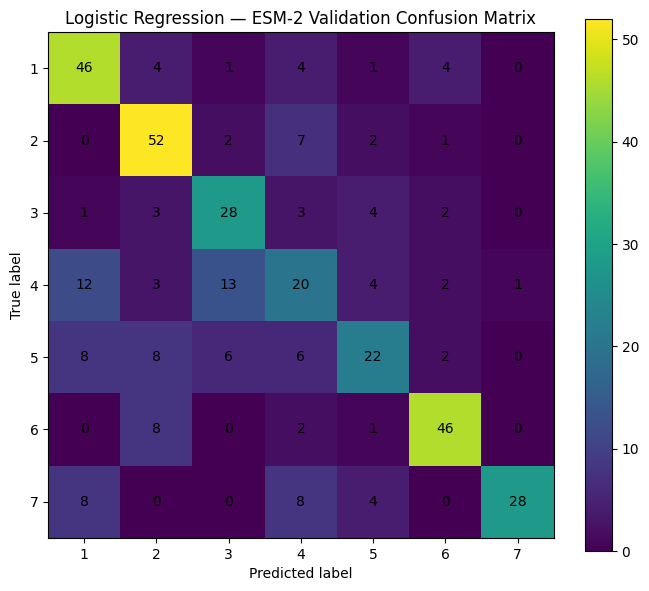


Training Linear SVM...

Metrics:
model: Linear SVM
accuracy: 0.6525
balanced_accuracy: 0.6443
macro_f1: 0.6399
weighted_f1: 0.6441

Classification report:
              precision    recall  f1-score   support

           1       0.57      0.73      0.64        60
           2       0.64      0.86      0.73        64
           3       0.53      0.66      0.59        41
           4       0.54      0.36      0.43        55
           5       0.62      0.40      0.49        52
           6       0.84      0.82      0.83        57
           7       0.89      0.67      0.76        48

    accuracy                           0.65       377
   macro avg       0.66      0.64      0.64       377
weighted avg       0.66      0.65      0.64       377



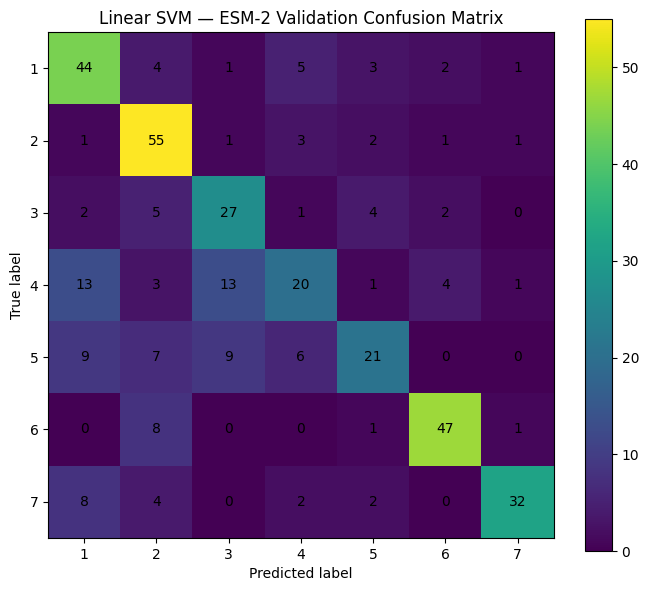


MODEL COMPARISON — ranked by validation macro-F1
              model  accuracy  balanced_accuracy  macro_f1  weighted_f1
         Linear SVM   0.65252           0.644279  0.639935     0.644123
Logistic Regression   0.64191           0.634165  0.633342     0.637338

Saved results to: /kaggle/working/esm2_results
Held-out test set remains untouched.


In [10]:

import numpy as np
import pandas as pd
import json
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("/kaggle/working/esm2_embeddings")
RESULTS_DIR = Path("/kaggle/working/esm2_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load cached embeddings and labels
train_data = np.load(OUTPUT_DIR / "train_embeddings.npz")
val_data = np.load(OUTPUT_DIR / "validation_embeddings.npz")

X_train = train_data["embeddings"]
y_train = train_data["labels"].astype(int)

X_val = val_data["embeddings"]
y_val = val_data["labels"].astype(int)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    ),
    "Linear SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=10000
        )
    )
}

results = []
reports = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_val, predictions),
        "macro_f1": f1_score(y_val, predictions, average="macro"),
        "weighted_f1": f1_score(y_val, predictions, average="weighted")
    }
    results.append(metrics)

    reports[name] = classification_report(
        y_val, predictions, output_dict=True, zero_division=0
    )

    print("\nMetrics:")
    for key, value in metrics.items():
        print(f"{key}: {value:.4f}" if isinstance(value, float)
              else f"{key}: {value}")

    print("\nClassification report:")
    print(classification_report(y_val, predictions, zero_division=0))

    # Save confusion matrix for each model
    cm = confusion_matrix(y_val, predictions, labels=[1, 2, 3, 4, 5, 6, 7])
    pd.DataFrame(
        cm,
        index=[f"True_{i}" for i in range(1, 8)],
        columns=[f"Pred_{i}" for i in range(1, 8)]
    ).to_csv(RESULTS_DIR / f"{name.lower().replace(' ', '_')}_confusion_matrix.csv")

    # Save plot
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{name} — ESM-2 Validation Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(7), range(1, 8))
    ax.set_yticks(range(7), range(1, 8))

    for i in range(7):
        for j in range(7):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(
        RESULTS_DIR / f"{name.lower().replace(' ', '_')}_confusion_matrix.png",
        dpi=160
    )
    plt.show()
    plt.close(fig)

results_df = pd.DataFrame(results).sort_values(
    "macro_f1", ascending=False
)
results_df.to_csv(RESULTS_DIR / "validation_model_comparison.csv", index=False)

with open(RESULTS_DIR / "classification_reports.json", "w") as f:
    json.dump(reports, f, indent=2)

print("\nMODEL COMPARISON — ranked by validation macro-F1")
print(results_df.to_string(index=False))
print("\nSaved results to:", RESULTS_DIR)
print("Held-out test set remains untouched.")


In [11]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
import pandas as pd
import json
from pathlib import Path

EMBED_DIR = Path("/kaggle/working/esm2_embeddings")
RESULTS_DIR = Path("/kaggle/working/esm2_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_data = __import__("numpy").load(EMBED_DIR / "train_embeddings.npz")
val_data = __import__("numpy").load(EMBED_DIR / "validation_embeddings.npz")

X_train = train_data["embeddings"]
y_train = train_data["labels"].astype(int)
X_val = val_data["embeddings"]
y_val = val_data["labels"].astype(int)

results = []
models = {}

for c_value in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:
    model = make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=c_value,
            class_weight="balanced",
            random_state=42,
            max_iter=10000
        )
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    row = {
        "C": c_value,
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_val, predictions),
        "macro_f1": f1_score(y_val, predictions, average="macro"),
        "weighted_f1": f1_score(y_val, predictions, average="weighted")
    }

    results.append(row)
    models[c_value] = model

results_df = pd.DataFrame(results).sort_values(
    "macro_f1", ascending=False
)

results_df.to_csv(
    RESULTS_DIR / "esm2_svm_c_tuning.csv",
    index=False
)

print(results_df.to_string(index=False))

best_c = float(results_df.iloc[0]["C"])
print(f"\nBest C by validation macro-F1: {best_c}")
print("Best validation macro-F1:",
      round(float(results_df.iloc[0]["macro_f1"]), 4))

with open(RESULTS_DIR / "esm2_svm_tuning_summary.json", "w") as f:
    json.dump({
        "selection_metric": "validation_macro_f1",
        "best_C": best_c,
        "best_validation_macro_f1":
            float(results_df.iloc[0]["macro_f1"]),
        "test_set_used": False,
        "all_results": results
    }, f, indent=2)

print("Tuning results saved to:", RESULTS_DIR)
print("Held-out test set remains untouched.")


    C  accuracy  balanced_accuracy  macro_f1  weighted_f1
 2.00  0.660477           0.652247  0.646287     0.650582
 0.10  0.655172           0.647468  0.644231     0.648349
 5.00  0.655172           0.645700  0.640132     0.645407
 1.00  0.652520           0.644279  0.639935     0.644123
 0.50  0.652520           0.644279  0.639935     0.644123
10.00  0.649867           0.640975  0.634240     0.638962
 0.01  0.641910           0.632661  0.632870     0.638674

Best C by validation macro-F1: 2.0
Best validation macro-F1: 0.6463
Tuning results saved to: /kaggle/working/esm2_results
Held-out test set remains untouched.


In [12]:

from pathlib import Path
import json

results_dir = Path("/kaggle/working/esm2_results")
results_dir.mkdir(parents=True, exist_ok=True)

selected_model = {
    "experiment": "ESM-2 embeddings + Linear SVM",
    "embedding_model": "facebook/esm2_t12_35M_UR50D",
    "embedding_dimension": 480,
    "classifier": "LinearSVC",
    "selected_C": 2.0,
    "class_weight": "balanced",
    "selection_metric": "validation_macro_f1",
    "validation_accuracy": 0.660477,
    "validation_balanced_accuracy": 0.652247,
    "validation_macro_f1": 0.646287,
    "validation_weighted_f1": 0.650582,
    "training_records": 1757,
    "validation_records": 377,
    "test_set_used_for_selection": False,
    "random_state": 42
}

output_path = results_dir / "selected_esm2_svm_config.json"

with open(output_path, "w") as f:
    json.dump(selected_model, f, indent=2)

print("Selected model configuration saved:")
print(output_path)
print(json.dumps(selected_model, indent=2))


Selected model configuration saved:
/kaggle/working/esm2_results/selected_esm2_svm_config.json
{
  "experiment": "ESM-2 embeddings + Linear SVM",
  "embedding_model": "facebook/esm2_t12_35M_UR50D",
  "embedding_dimension": 480,
  "classifier": "LinearSVC",
  "selected_C": 2.0,
  "class_weight": "balanced",
  "selection_metric": "validation_macro_f1",
  "validation_accuracy": 0.660477,
  "validation_balanced_accuracy": 0.652247,
  "validation_macro_f1": 0.646287,
  "validation_weighted_f1": 0.650582,
  "training_records": 1757,
  "validation_records": 377,
  "test_set_used_for_selection": false,
  "random_state": 42
}


In [13]:

from pathlib import Path
import numpy as np

EMBED_DIR = Path("/kaggle/working/esm2_embeddings")

for name in ["train", "validation", "test"]:
    path = EMBED_DIR / f"{name}_embeddings.npz"
    if not path.exists():
        print(f"MISSING: {path}")
    else:
        data = np.load(path)
        print(
            f"{name}: embeddings={data['embeddings'].shape}, "
            f"labels={data['labels'].shape}"
        )


train: embeddings=(1757, 480), labels=(1757,)
validation: embeddings=(377, 480), labels=(377,)
MISSING: /kaggle/working/esm2_embeddings/test_embeddings.npz


In [15]:
print("Model loaded:", "model" in globals())
print("Tokenizer loaded:", "tokenizer" in globals())
print("Test dataframe loaded:", "test_df" in globals())
print("Window function names:",
      [name for name in globals()
       if "window" in name.lower() and callable(globals()[name])])

Model loaded: True
Tokenizer loaded: True
Test dataframe loaded: False
Window function names: ['count_windows', 'make_windows']


In [16]:
import pandas as pd

TEST_PATH = "/kaggle/input/datasets/s0ulraag/protein-set/test.csv"
test_df = pd.read_csv(TEST_PATH)

print("Test shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
print(test_df[["Entry", "Sequence", "label"]].head())

Test shape: (539, 35)
Columns: ['Entry', 'Entry Name', 'Protein names', 'Organism', 'Organism (ID)', 'Length', 'Sequence', 'EC number', 'Annotation', 'Protein existence', 'GO', 'Gene Ontology (molecular function)', 'Gene Ontology (biological process)', 'Gene Ontology (cellular component)', 'retrieval_query', 'retrieval_ec_class', 'retrieval_timestamp_utc', 'source_url', 'Annotation score', 'complete_ec_numbers', 'top_level_classes', 'n_top_level_classes', 'label', 'annotation_class_status', 'retrieval_class_matches_annotation', 'sequence_clean', 'sequence_length_actual', 'ambiguous_residue_count', 'invalid_residue_count', 'has_invalid_characters', 'is_empty_sequence', 'exact_sequence_hash', 'is_exact_duplicate', 'length_matches_annotation', 'cluster_id']
    Entry                                           Sequence  label
0  C9JRZ8  MATFVELSTKAKMPIVGLGTWRSLLGKVKEAVKVAIDAEYRHIDCA...      1
1  O14756  MWLYLAAFVGLYYLLHWYRERQVVSHLQDKYVFITGCDSGFGNLLA...      1
2  O43593  MESTPSFLKGTPTWEKTAPE

In [18]:
import inspect
import torch

print("Window functions:")
print("make_windows:", inspect.signature(make_windows))
print("count_windows:", inspect.signature(count_windows))

print("\nESM-2 model variables:")
for name in ["esm_model", "tokenizer", "model"]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", type(obj).__name__)

print("\nDevice:")
if "esm_model" in globals():
    print(next(esm_model.parameters()).device)
elif "model" in globals() and hasattr(model, "parameters"):
    print(next(model.parameters()).device)
else:
    print("Inspect the model variables above.")

print("\nWindowing constants:")
for name in [
    "MAX_LENGTH", "MAX_TOKENS", "WINDOW_SIZE",
    "WINDOW_STRIDE", "BATCH_SIZE", "device"
]:
    if name in globals():
        print(f"{name} =", globals()[name])

Window functions:
make_windows: (sequence)
count_windows: (length)

ESM-2 model variables:
esm_model -> EsmModel
tokenizer -> EsmTokenizer
model -> Pipeline

Device:
cuda:0

Windowing constants:
WINDOW_SIZE = 1000
BATCH_SIZE = 4


In [20]:
sample_sequence = str(test_df.iloc[0]["Sequence"]).strip().upper()
sample_windows = make_windows(sample_sequence)

print("Sequence length:", len(sample_sequence))
print("Number of windows:", len(sample_windows))
print("Window type:", type(sample_windows[0]))
print("First window preview:", repr(sample_windows[0])[:300])

Sequence length: 316
Number of windows: 1
Window type: <class 'tuple'>
First window preview: (0, 'MATFVELSTKAKMPIVGLGTWRSLLGKVKEAVKVAIDAEYRHIDCAYFYENQHEVGEAIQEKIQEKAVMREDLFIVSKVWPTFFERPLVRKAFEKTLKDLKLSYLDVYLIHWPQGFKTGDDFFPKDDKGNMISGKGTFLDAWEAMEELVDEGLVKALGVSNFNHFQIERLLNKPGLKYKPVTNQVECHPYLTQEKLIQYCHSKGITVTAYSPLGSPDRPWAKPEDPSLLEDPKIKEIAAKHKKTTAQVLIRFHIQRNVTVIPKSMTPAHIVENIQVFDFKLSDEEMATILSFNRN


In [26]:

import numpy as np
import torch
import time
from pathlib import Path

EMBED_DIR = Path("/kaggle/working/esm2_embeddings")
EMBED_DIR.mkdir(parents=True, exist_ok=True)

assert "test_df" in globals(), "Load test_df first."
assert "Sequence" in test_df.columns and "label" in test_df.columns
assert "esm_model" in globals() and "tokenizer" in globals()
assert "make_windows" in globals() and "BATCH_SIZE" in globals()

esm_model.eval()
device = next(esm_model.parameters()).device

all_embeddings = []
all_labels = []
start_time = time.time()

for row_idx, row in test_df.reset_index(drop=True).iterrows():
    sequence = str(row["Sequence"]).strip().upper()
    label = int(row["label"])

    windows = make_windows(sequence)
    if not windows:
        raise ValueError(f"No windows generated for test row {row_idx}")

    # make_windows may return (start_position, sequence_window) tuples.
    batch_windows = [
        w[1] if isinstance(w, tuple) else w
        for w in windows
    ]
    batch_embeddings = []

    for batch_start in range(0, len(batch_windows), BATCH_SIZE):
        batch = batch_windows[batch_start:batch_start + BATCH_SIZE]

        encoded = tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=1024
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}

        with torch.inference_mode():
            outputs = esm_model(**encoded)
            hidden = outputs.last_hidden_state

            attention_mask = encoded["attention_mask"].bool()
            special_mask = torch.zeros_like(attention_mask)

            for token_id in tokenizer.all_special_ids:
                special_mask |= encoded["input_ids"].eq(token_id)

            residue_mask = attention_mask & ~special_mask
            mask = residue_mask.unsqueeze(-1).to(hidden.dtype)

            summed = (hidden * mask).sum(dim=1)
            counts = mask.sum(dim=1).clamp(min=1)
            pooled = summed / counts

        batch_embeddings.extend(
            pooled.detach().cpu().numpy().astype(np.float32)
        )

    # One mean embedding per protein, even when it has multiple windows.
    protein_embedding = np.mean(
        np.stack(batch_embeddings, axis=0), axis=0
    )

    all_embeddings.append(protein_embedding)
    all_labels.append(label)

    if (row_idx + 1) % 50 == 0 or row_idx + 1 == len(test_df):
        print(f"Test: processed {row_idx + 1}/{len(test_df)} proteins")

X_test = np.stack(all_embeddings).astype(np.float32)
y_test = np.asarray(all_labels, dtype=np.int64)

assert X_test.shape == (len(test_df), 480), X_test.shape
assert y_test.shape == (len(test_df),)
assert np.isfinite(X_test).all(), "Non-finite embeddings detected."

unique_count = np.unique(X_test, axis=0).shape[0]

print("\nEmbedding integrity check")
print("Shape:", X_test.shape)
print("Unique embedding rows:", unique_count)
print("Standard deviation:", float(X_test.std()))
print("First 5 row norms:", np.linalg.norm(X_test[:5], axis=1))

if unique_count == 1:
    raise RuntimeError(
        "All test embeddings are identical. Do not evaluate the model; "
        "inspect the model outputs and window function."
    )

output_path = EMBED_DIR / "test_embeddings.npz"
np.savez_compressed(
    output_path,
    embeddings=X_test,
    labels=y_test
)

print("\nTest embeddings regenerated and saved.")
print("Elapsed seconds:", round(time.time() - start_time, 2))
print("Saved to:", output_path)


Test: processed 50/539 proteins
Test: processed 100/539 proteins
Test: processed 150/539 proteins
Test: processed 200/539 proteins
Test: processed 250/539 proteins
Test: processed 300/539 proteins
Test: processed 350/539 proteins
Test: processed 400/539 proteins
Test: processed 450/539 proteins
Test: processed 500/539 proteins
Test: processed 539/539 proteins

Embedding integrity check
Shape: (539, 480)
Unique embedding rows: 539
Standard deviation: 0.24880383908748627
First 5 row norms: [4.196405  3.6252546 6.1795044 4.906949  4.5197935]

Test embeddings regenerated and saved.
Elapsed seconds: 18.19
Saved to: /kaggle/working/esm2_embeddings/test_embeddings.npz


FINAL HELD-OUT TEST RESULTS
experiment: ESM-2 + StandardScaler + Linear SVM
selected_C: 2.0
training_records: 2134
test_records: 539
test_accuracy: 0.7142857142857143
test_balanced_accuracy: 0.7111902134101492
test_macro_f1: 0.7034687011919823
test_weighted_f1: 0.7093489887162305
training_seconds: 33.419
test_used_for_model_selection: False
random_state: 42

Classification report:
              precision    recall  f1-score   support

           1       0.63      0.58      0.60        72
           2       0.82      0.82      0.82        85
           3       0.66      0.79      0.72        62
           4       0.56      0.59      0.58        75
           5       0.56      0.43      0.49        81
           6       0.76      0.86      0.81        71
           7       0.90      0.90      0.90        93

    accuracy                           0.71       539
   macro avg       0.70      0.71      0.70       539
weighted avg       0.71      0.71      0.71       539



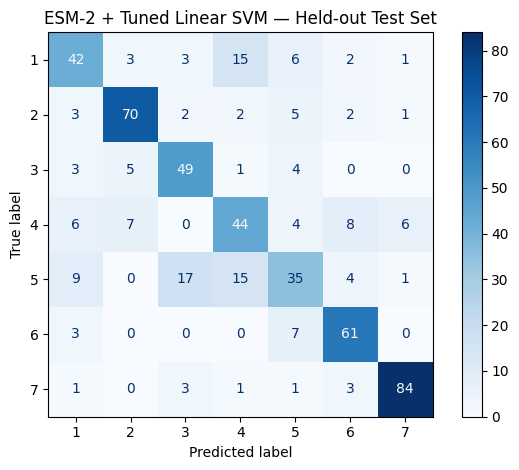


Results saved to: /kaggle/working/esm2_results


In [28]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

EMBED_DIR = Path("/kaggle/working/esm2_embeddings")
RESULTS_DIR = Path("/kaggle/working/esm2_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train = np.load(EMBED_DIR / "train_embeddings.npz")
val = np.load(EMBED_DIR / "validation_embeddings.npz")
test = np.load(EMBED_DIR / "test_embeddings.npz")

X_train, y_train = train["embeddings"], train["labels"].astype(int)
X_val, y_val = val["embeddings"], val["labels"].astype(int)
X_test, y_test = test["embeddings"], test["labels"].astype(int)

assert X_train.shape == (1757, 480)
assert X_val.shape == (377, 480)
assert X_test.shape == (539, 480)
assert np.isfinite(X_test).all()

# Combine training and validation data only.
X_fit = np.concatenate([X_train, X_val], axis=0)
y_fit = np.concatenate([y_train, y_val], axis=0)

final_model = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=2.0,
        class_weight="balanced",
        random_state=42,
        max_iter=10000
    )
)

start = time.time()
final_model.fit(X_fit, y_fit)
training_seconds = time.time() - start

# First and only final evaluation on the held-out test set.
y_pred = final_model.predict(X_test)

metrics = {
    "experiment": "ESM-2 + StandardScaler + Linear SVM",
    "selected_C": 2.0,
    "training_records": int(len(y_fit)),
    "test_records": int(len(y_test)),
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred)
    ),
    "test_macro_f1": float(
        f1_score(y_test, y_pred, average="macro")
    ),
    "test_weighted_f1": float(
        f1_score(y_test, y_pred, average="weighted")
    ),
    "training_seconds": round(training_seconds, 3),
    "test_used_for_model_selection": False,
    "random_state": 42
}

print("FINAL HELD-OUT TEST RESULTS")
print("=" * 55)
for key, value in metrics.items():
    print(f"{key}: {value}")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred, labels=list(range(1, 8)), zero_division=0
))

with open(RESULTS_DIR / "final_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

report = classification_report(
    y_test, y_pred, labels=list(range(1, 8)),
    output_dict=True, zero_division=0
)
pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "final_test_classification_report.csv"
)

cm = confusion_matrix(y_test, y_pred, labels=list(range(1, 8)))
pd.DataFrame(
    cm,
    index=[f"True_{i}" for i in range(1, 8)],
    columns=[f"Predicted_{i}" for i in range(1, 8)]
).to_csv(RESULTS_DIR / "final_test_confusion_matrix.csv")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=list(range(1, 8))
)
disp.plot(cmap="Blues", values_format="d")
plt.title("ESM-2 + Tuned Linear SVM — Held-out Test Set")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "final_test_confusion_matrix.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("\nResults saved to:", RESULTS_DIR)


In [23]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Reuse final_model and the arrays from the previous evaluation cell.
splits = {
    "Train": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test),
}

print("=" * 65)
print("1. LABEL DISTRIBUTION")
print("=" * 65)

for name, (_, y) in splits.items():
    print(f"\n{name}:")
    print(pd.Series(y).value_counts().sort_index().to_dict())

print("\n" + "=" * 65)
print("2. EMBEDDING STATISTICS")
print("=" * 65)

for name, (X, _) in splits.items():
    print(f"\n{name}")
    print("Shape:", X.shape)
    print("All finite:", bool(np.isfinite(X).all()))
    print("Mean:", round(float(X.mean()), 6))
    print("Standard deviation:", round(float(X.std()), 6))
    print("Minimum:", round(float(X.min()), 6))
    print("Maximum:", round(float(X.max()), 6))
    print("Mean row norm:", round(float(np.linalg.norm(X, axis=1).mean()), 6))
    print("Unique rows:", len(np.unique(X, axis=0)))

print("\n" + "=" * 65)
print("3. PREDICTIONS ON EACH SPLIT")
print("=" * 65)

for name, (X, y) in splits.items():
    pred = final_model.predict(X)

    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y, pred), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y, pred), 4))
    print("Macro F1:", round(f1_score(y, pred, average="macro"), 4))
    print("Predicted class counts:",
          pd.Series(pred).value_counts().sort_index().to_dict())

print("\n" + "=" * 65)
print("4. MEAN EMBEDDING DISTANCE BETWEEN SPLITS")
print("=" * 65)

for name, (X, _) in splits.items():
    print(
        f"{name}: mean feature vector (first 10 dimensions):",
        np.round(X.mean(axis=0)[:10], 4)
    )

print("\nDiagnostic complete. No model or data files were modified.")


1. LABEL DISTRIBUTION

Train:
{1: 253, 2: 263, 3: 203, 4: 246, 5: 252, 6: 282, 7: 258}

Validation:
{1: 60, 2: 64, 3: 41, 4: 55, 5: 52, 6: 57, 7: 48}

Test:
{1: 72, 2: 85, 3: 62, 4: 75, 5: 81, 6: 71, 7: 93}

2. EMBEDDING STATISTICS

Train
Shape: (1757, 480)
All finite: True
Mean: 0.005231
Standard deviation: 0.238289
Minimum: -2.607493
Maximum: 6.180962
Mean row norm: 5.160276
Unique rows: 1757

Validation
Shape: (377, 480)
All finite: True
Mean: 0.005348
Standard deviation: 0.239837
Minimum: -2.596582
Maximum: 6.010397
Mean row norm: 5.204095
Unique rows: 377

Test
Shape: (539, 480)
All finite: True
Mean: 0.004503
Standard deviation: 0.191486
Minimum: -0.706551
Maximum: 3.27586
Mean row norm: 4.196405
Unique rows: 1

3. PREDICTIONS ON EACH SPLIT

Train
Accuracy: 1.0
Balanced accuracy: 1.0
Macro F1: 1.0
Predicted class counts: {1: 253, 2: 263, 3: 203, 4: 246, 5: 252, 6: 282, 7: 258}

Validation
Accuracy: 1.0
Balanced accuracy: 1.0
Macro F1: 1.0
Predicted class counts: {1: 60, 2: 64, 3:

In [27]:
test = np.load(
    "/kaggle/working/esm2_embeddings/test_embeddings.npz"
)
X_test = test["embeddings"]
y_test = test["labels"]

print("Test embedding shape:", X_test.shape)
print("Unique rows:", np.unique(X_test, axis=0).shape[0])

Test embedding shape: (539, 480)
Unique rows: 539


In [24]:

print("Test rows:", len(test_df))
print("Unique protein sequences:", test_df["Sequence"].nunique())
print("Missing sequences:", test_df["Sequence"].isna().sum())

print("\nFirst 5 sequence lengths:")
print(test_df["Sequence"].astype(str).str.len().head().tolist())

print("\nFirst 3 sequence previews:")
for sequence in test_df["Sequence"].head(3):
    print(str(sequence)[:80])
    print()


Test rows: 539
Unique protein sequences: 539
Missing sequences: 0

First 5 sequence lengths:
[316, 317, 1189, 331, 187]

First 3 sequence previews:
MATFVELSTKAKMPIVGLGTWRSLLGKVKEAVKVAIDAEYRHIDCAYFYENQHEVGEAIQEKIQEKAVMREDLFIVSKVW

MWLYLAAFVGLYYLLHWYRERQVVSHLQDKYVFITGCDSGFGNLLARQLDARGLRVLAACLTEKGAEQLRGQTSDRLETV

MESTPSFLKGTPTWEKTAPENGIVRQEPGSPPRDGLHHGPLCLGEPAPFWRGVLSTPDSWLPPGFPQGPKDMLPLVEGEG



In [25]:

import numpy as np

path = "/kaggle/working/esm2_embeddings/test_embeddings.npz"

with np.load(path) as data:
    print("Stored arrays:", data.files)

    embeddings = data["embeddings"]
    labels = data["labels"]

    print("Embedding shape:", embeddings.shape)
    print("Label shape:", labels.shape)
    print("Unique embedding rows:", np.unique(embeddings, axis=0).shape[0])
    print("First 5 row norms:", np.linalg.norm(embeddings[:5], axis=1))
    print("First 5 label values:", labels[:5])


Stored arrays: ['embeddings', 'labels']
Embedding shape: (539, 480)
Label shape: (539,)
Unique embedding rows: 1
First 5 row norms: [4.196405 4.196405 4.196405 4.196405 4.196405]
First 5 label values: [1 1 1 1 1]


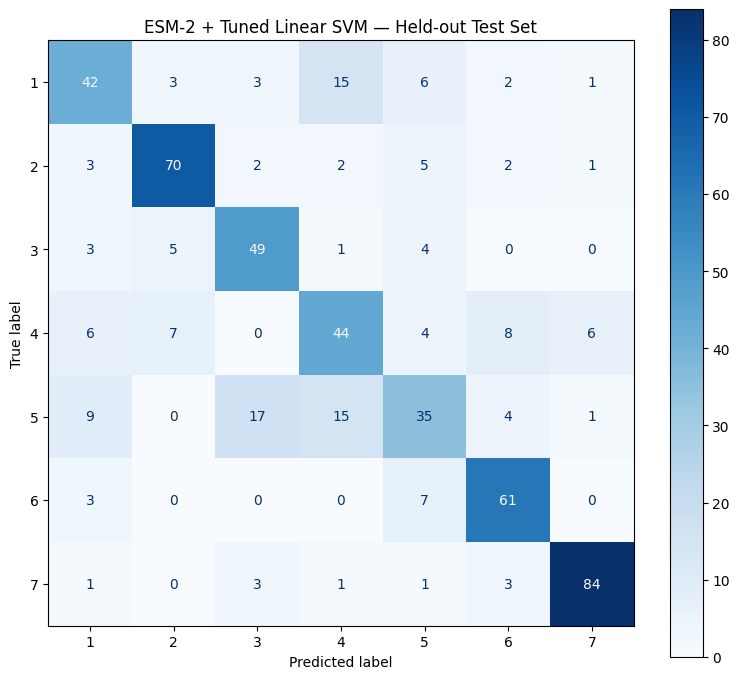

Saved files:
classification_report.csv - 705 bytes
classification_reports.json - 2874 bytes
confusion_matrix.csv - 242 bytes
confusion_matrix.png - 77662 bytes
esm2_svm_c_tuning.csv - 607 bytes
esm2_svm_tuning_summary.json - 1504 bytes
final_test_classification_report.csv - 705 bytes
final_test_confusion_matrix.csv - 242 bytes
final_test_confusion_matrix.png - 68722 bytes
final_test_metrics.json - 508 bytes
linear_svm_confusion_matrix.csv - 206 bytes
linear_svm_confusion_matrix.png - 51085 bytes
logistic_regression_confusion_matrix.csv - 206 bytes
logistic_regression_confusion_matrix.png - 54957 bytes
selected_esm2_svm_config.json - 529 bytes
validation_model_comparison.csv - 235 bytes

Metrics:
{
  "experiment": "ESM-2 embeddings + StandardScaler + Linear SVM",
  "embedding_model": "facebook/esm2_t12_35M_UR50D",
  "classifier": "LinearSVC",
  "selected_C": 2.0,
  "class_weight": "balanced",
  "selection_metric": "validation_macro_f1",
  "training_records": 2134,
  "test_records": 539,

In [29]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RESULTS_DIR = Path("/kaggle/working/esm2_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Use the corrected test embeddings and the final selected model.
test_data = np.load(
    "/kaggle/working/esm2_embeddings/test_embeddings.npz"
)
X_test = test_data["embeddings"]
y_test = test_data["labels"]

assert X_test.shape == (539, 480), X_test.shape
assert len(y_test) == 539
assert np.unique(X_test, axis=0).shape[0] > 1

y_pred = final_model.predict(X_test)
labels = [1, 2, 3, 4, 5, 6, 7]

metrics = {
    "experiment": "ESM-2 embeddings + StandardScaler + Linear SVM",
    "embedding_model": "facebook/esm2_t12_35M_UR50D",
    "classifier": "LinearSVC",
    "selected_C": 2.0,
    "class_weight": "balanced",
    "selection_metric": "validation_macro_f1",
    "training_records": 2134,
    "test_records": 539,
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred)
    ),
    "macro_f1": float(
        f1_score(y_test, y_pred, average="macro")
    ),
    "weighted_f1": float(
        f1_score(y_test, y_pred, average="weighted")
    ),
    "test_used_for_model_selection": False,
    "random_state": 42
}

with open(RESULTS_DIR / "final_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

report = classification_report(
    y_test,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(report).T.to_csv(
    RESULTS_DIR / "classification_report.csv"
)

cm = confusion_matrix(y_test, y_pred, labels=labels)
pd.DataFrame(
    cm,
    index=[f"True_{x}" for x in labels],
    columns=[f"Predicted_{x}" for x in labels]
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=True)
ax.set_title("ESM-2 + Tuned Linear SVM — Held-out Test Set")
fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved files:")
for path in sorted(RESULTS_DIR.iterdir()):
    print(path.name, "-", path.stat().st_size, "bytes")

print("\nMetrics:")
print(json.dumps(metrics, indent=2))
